# 06 · Robustness

**Question:** does the headline (H0 shift, Model 3, analysis half: next shot 1.50 ft farther after a
make than after a miss) survive deliberate attempts to break it?

Survival rule and counting (D-045, D-046) were written by Massimo before this notebook ran. The
verdict on what counts as fragile is his.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hothand import core, robustness as rb
from hothand.config import FIGURES, PROCESSED, load_config
from hothand.features import CLUSTERS, FEATURES, SHOTS
from hothand.segments import PLAYER_SEASONS

pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 70)
cfg = load_config()
print("Python:", sys.executable)
print("pandas:", pd.__version__)
HALF = "analysis"
f = pd.read_parquet(FEATURES)
shots = pd.read_parquet(SHOTS)
ps, cl = pd.read_csv(PLAYER_SEASONS), pd.read_csv(CLUSTERS)

Python: /Users/massimovitale/Desktop/nba-shot-selection-hot-hand/.venv/bin/python
pandas: 3.0.6


## 1. Every variation (one change at a time, Model 3)

In [2]:
table = rb.run_variations(f, shots, ps, cl, cfg, HALF, cfg["robustness"]["bootstrap_draws"])
baseline = table.loc[table.family == "baseline", "estimate"].iloc[0]
table["change_from_baseline"] = table.estimate - baseline
table["contains_baseline"] = (table.ci_low <= baseline) & (baseline <= table.ci_high)
print(f"Baseline (Model 3, {HALF} half): {baseline:.3f} ft")
table[["family", "variation", "counted", "estimate", "ci_low", "ci_high", "change_from_baseline",
       "contains_baseline", "n_pairs", "n_players"]].round(3)

Baseline (Model 3, analysis half): 1.495 ft


,family,variation,counted,estimate,ci_low,ci_high,change_from_baseline,contains_baseline,n_pairs,n_players
0,baseline,"Model 3, analysis rules",False,1.495,1.362,1.628,0.000,True,535416,1199
1,pair gap,max gap 60 s,True,2.041,1.847,2.235,0.546,False,211389,1164
2,pair gap,max gap 120 s,True,1.745,1.592,1.898,0.250,False,383712,1188
3,pair gap,max gap 480 s,True,1.370,1.250,1.491,-0.125,False,628761,1203
4,pair gap,max gap: none,True,1.227,1.117,1.337,-0.268,False,732915,1206
5,same period only,pairs within one period,True,1.576,1.436,1.716,0.081,True,486841,1198
6,heaves and garbage time,drop last 3 s of any period and garbage time,True,1.516,1.380,1.653,0.021,True,507382,1163
7,season by season,2018-19,True,1.528,1.340,1.717,0.033,True,69627,506
8,season by season,2019-20,True,1.644,1.418,1.871,0.149,True,60047,508
9,season by season,2020-21,True,1.469,1.250,1.689,-0.026,True,61984,515


## 2. Survival rule (D-045): automated check

In [3]:
check = rb.survival(table, baseline, cfg["robustness"]["survival_share"])
pd.Series(check)

counted_variations                                                                  24
all_positive                                                                      True
share_containing_baseline                                                     0.833333
required_share                                                                     0.8
rule_met                                                                          True
variations_not_containing    max gap 60 s; max gap 120 s; max gap 480 s; max gap: none
dtype: object

## 3. Specification curve (playbook 7.4)

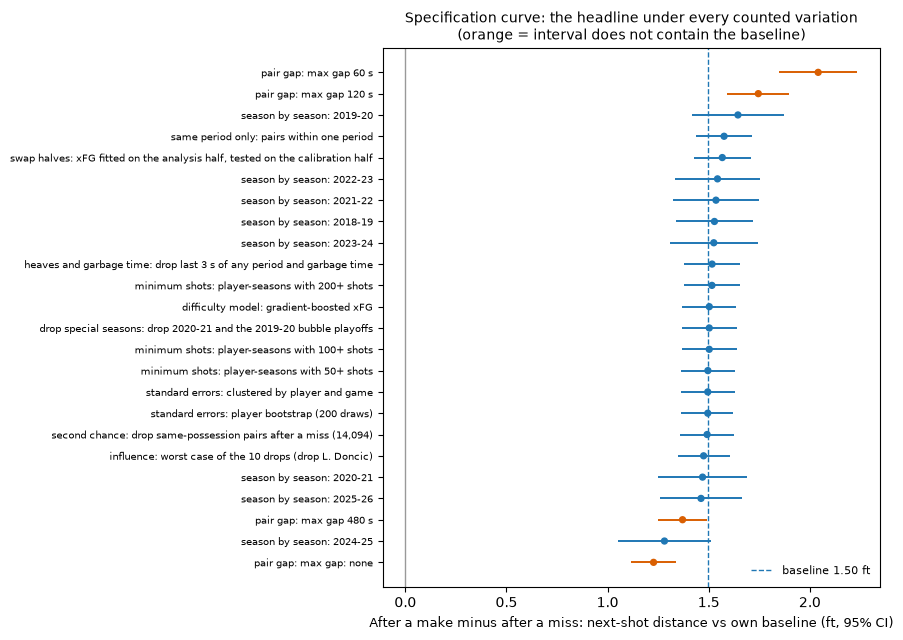

In [4]:
c = table[table.counted].sort_values("estimate").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(c))
colors = np.where(c.contains_baseline, "#1f77b4", "#d95f02")
ax.hlines(y, c.ci_low, c.ci_high, colors=colors, lw=1.4)
ax.scatter(c.estimate, y, c=colors, s=18, zorder=3)
ax.axvline(baseline, color="#1f77b4", ls="--", lw=1, label=f"baseline {baseline:.2f} ft")
ax.axvline(0, color="#999", lw=1)
ax.set_yticks(y, [f"{a}: {b}" for a, b in zip(c.family, c.variation)], fontsize=7.5)
ax.set_xlabel("After a make minus after a miss: next-shot distance vs own baseline (ft, 95% CI)",
              fontsize=9)
ax.set_title("Specification curve: the headline under every counted variation\n"
             "(orange = interval does not contain the baseline)", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "stage7_specification_curve.png", dpi=150)

## 4. H2 and H3 gaps under the same variations (reported without a verdict, D-046)

In [5]:
table.loc[table.h2_low_minus_high.notna(), ["family", "variation", "h2_low_minus_high", "h2_ci_low",
           "h2_ci_high", "h3_rimbigs_minus_3pt", "h3_ci_low", "h3_ci_high"]].round(3)

,family,variation,h2_low_minus_high,h2_ci_low,h2_ci_high,h3_rimbigs_minus_3pt,h3_ci_low,h3_ci_high
1,pair gap,max gap 60 s,-0.696,-1.092,-0.299,-1.764,-2.365,-1.162
2,pair gap,max gap 120 s,-0.435,-0.740,-0.130,-1.293,-1.775,-0.812
3,pair gap,max gap 480 s,-0.418,-0.651,-0.184,-0.974,-1.344,-0.603
4,pair gap,max gap: none,-0.470,-0.683,-0.257,-0.851,-1.190,-0.513
5,same period only,pairs within one period,-0.489,-0.763,-0.214,-1.096,-1.550,-0.642
6,heaves and garbage time,drop last 3 s of any period and garbage time,-0.523,-0.787,-0.258,-1.034,-1.461,-0.608
7,season by season,2018-19,-0.433,-0.962,0.095,-0.585,-1.180,0.010
8,season by season,2019-20,-0.326,-0.931,0.280,-1.097,-1.901,-0.293
9,season by season,2020-21,-0.411,-0.977,0.156,-0.793,-1.600,0.014
10,season by season,2021-22,-0.820,-1.387,-0.252,-1.239,-2.224,-0.254


## 5. Not counted: other clusterings for H3 (D-046)

In [6]:
clusters_alt = rb.cluster_variants(f, shots, cfg, HALF)
clusters_alt.round(5)

,family,variation,counted,statistic,p_value,n_pairs,n_players
0,cluster count (not counted),"k = 3, seed 20261014",False,25.15209,0.00000,425852,505
1,cluster count (not counted),"k = 5, seed 20261014",False,39.06280,0.00000,425852,505
2,cluster count (not counted),"k = 4, seed 20261015",False,24.40295,0.00002,425852,505
3,cluster count (not counted),"k = 4, seed 20261016",False,24.25362,0.00002,425852,505


## 6. Placebo tests (playbook 7.3)

**Future-result placebo (D-048):** the shot after the next one cannot influence where the next shot
was taken, so a clear effect here would signal confounding in the design. **Shuffled-order placebo:**
the Stage 5 permutation test already shows the observed shift against 1,000 shuffles
(`reports/figures/stage5_permutation_null.png`).

In [7]:
d = core.prepare(f, cfg, HALF)
placebo = rb.future_placebo(d)
pd.Series(placebo).round(4)

estimate          0.0682
ci_low            0.0009
ci_high           0.1355
p_value           0.0470
n_pairs      332710.0000
n_players      1140.0000
dtype: float64

## 7. Save

In [8]:
placebo_row = pd.DataFrame([{"half": HALF, "family": "placebo",
                             "variation": "future result (shot after the next one made)",
                             "counted": False, **placebo}])
check_row = pd.DataFrame([{"half": HALF, "family": "survival check (automated)",
                           "variation": "D-045", "counted": False,
                           "estimate": check["share_containing_baseline"],
                           "note": f"all positive: {check['all_positive']}; rule met: {check['rule_met']}"}])
clusters_alt.insert(0, "half", HALF)
out = pd.concat([table, clusters_alt, placebo_row, check_row], ignore_index=True)
out.to_csv(PROCESSED / "results_robustness.csv", index=False)
print(f"{len(out)} rows -> data/processed/results_robustness.csv")

43 rows -> data/processed/results_robustness.csv
